[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L4/BA_L4_utility/BA_L4_utility.ipynb)

# BA_L4_utility: Event-Level Utility of an Early-Warning Alarm

*Quantlet of Lecture 4, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Credit v(l) given to the first valid alert as a function of its lead time l in hours before a depeg event, as in the event-level utility U of the stablecoin early-warning protocol, with a worked example of four events. Analytical, no data.

In [1]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

Setup: chart style and colours of the slides, and a `save()` helper that puts one legend below the figure.

In [4]:
import matplotlib
import matplotlib.dates as mdates
from scipy import stats

# the slide charts use matplotlib's default sizes with 10-point text and an 8-point legend
plt.rcParams.update({'font.size': 10, 'axes.labelsize': 'medium', 'axes.titlesize': 'large', 'axes.linewidth': 0.8,
                     'lines.linewidth': 1.5, 'legend.fontsize': 8})
COL = {'USDT': GREEN, 'USDC': BLUE, 'DAI': GOLD}


def save(fig, name, bottom, ncol=3):
    """One legend for all panels below the plot (as on the slide), then save to OUT_PATH and show."""
    fig.legend(loc='lower center', ncol=ncol, frameon=False, fontsize=8)
    fig.tight_layout(rect=(0, bottom, 1, 1))
    save_fig(fig, name)

## What the chart shows

An alarm is evaluated per event, not per hour. Alerts are the hours with a score above a threshold; a 24-hour refractory period merges them into alert episodes.
An event $e$ at time $\tau_e$ is detected if an alert falls in $[\tau_e - 24\text{h}, \tau_e - 1\text{h}]$; its lead $\ell_e$ is the number of hours before $\tau_e$. All other alert episodes are false; $F_m$ is the number of false alerts per month. The utility is

$$ U = \frac{1}{|E|}\sum_{e \in E} v(\ell_e) - 0.05\,F_m, \qquad v(\ell) = 0.10 + 0.90\,\frac{\ell - 1}{23} \;\text{ for } 1 \leq \ell \leq 24, \text{ else } 0 . $$

The chart shows the credit $v(\ell)$ and the valid warning window.

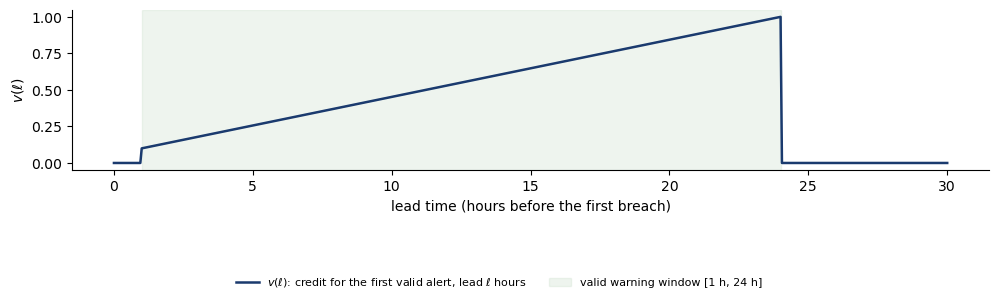

In [5]:
def v(l):
    """Credit for the first valid alert with a lead of l hours."""
    l = np.asarray(l, dtype=float)
    return np.where((l >= 1) & (l <= 24), 0.10 + 0.90 * (l - 1) / 23, 0.0)


fig, ax = plt.subplots(figsize=(10, 3.0))
ll = np.linspace(0, 30, 601)
ax.plot(ll, v(ll), color=BLUE, lw=1.8, label=r'$v(\ell)$: credit for the first valid alert, lead $\ell$ hours')
ax.axvspan(1, 24, color=GREEN, alpha=0.08, label='valid warning window [1 h, 24 h]')
ax.set_xlabel('lead time (hours before the first breach)'); ax.set_ylabel(r'$v(\ell)$')
save(fig, 'ba_l4_utility', 0.22)

## Worked example

Four events; the first valid alerts come 14 h, 2 h, never and 20 h before the breach; there are 2.5 false alerts per month.

In [6]:
leads = np.array([14, 2, 0, 20])
print('lead of the first valid alert (h):', leads.tolist())
print('credit per event v(l):', np.round(v(leads), 3).tolist())
print(f'mean credit = {v(leads).mean():.3f}; utility U = {v(leads).mean():.3f} - 0.05 x 2.5 = {v(leads).mean() - 0.05 * 2.5:.3f}')

lead of the first valid alert (h): [14, 2, 0, 20]
credit per event v(l): [0.609, 0.139, 0.0, 0.843]
mean credit = 0.398; utility U = 0.398 - 0.05 x 2.5 = 0.273


**How to read it:** an alert after the breach, or more than 24 hours before it, earns nothing; earlier valid alerts earn more.
One more false alert per month costs 0.05, about the credit for detecting one extra event (out of four) with a 2-hour lead.